# El Ojo del Árbitro Digital
El objetivo es desarrollar un sistema de visión artificial que pueda interpretar un partido de fútbol. El algoritmo deberá procesar un video, tomar aleatoriamente una imagen y sobre la imagen tomada resaltar los elementos clave del juego utilizando códigos de colores específicos si aparecen en dicha imagen.

## Especificaciones Visuales
Para que la computadora identifique correctamente cada elemento, el script de Python debe cumplir con el siguiente código de colores:

**Jugadores:** Dibujar un su contorno de color azul alrededor de cada jugador detectado. No es necesario realizar seguimiento individual de cada jugador. Esto significa que sólo deben detectar si hay  uno o más jugadores y marcar su contorno
**La Pelota:** Identificarla y marcar su contorno de color rojo si existe en la imagen tomada al azar
Límites de la Cancha: Detectar las líneas del campo (laterales, fondo, áreas) y resaltarlas con color verde.

SI POR ALGÚN MOTIVO EN LA IMAGEN NO APARECE NINGUNO DE LOS ELEMENTOS, NO SE DEBE MARCAR NADA

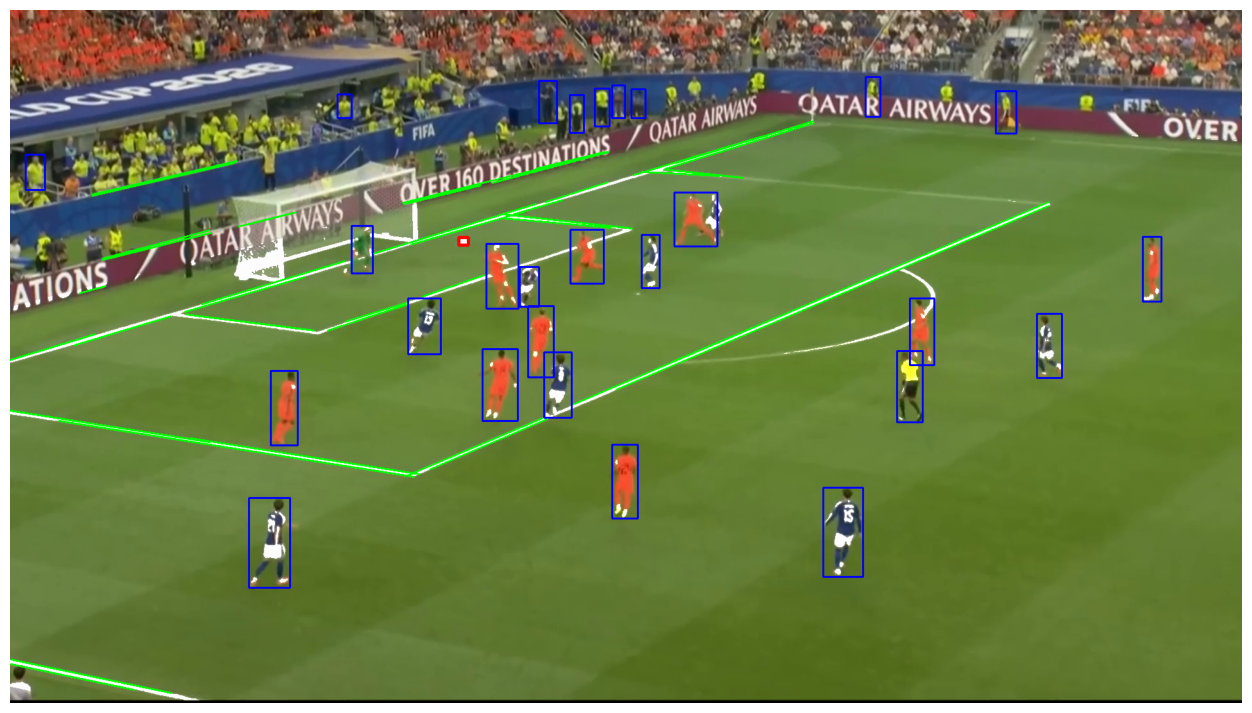

In [ ]:
!pip install -q ultralytics
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

VIDEO = "VideoHolandaJapon_Contraste.mp4"
modelo = YOLO("yolov8s.pt")

# Aislar un fotograma cualquiera
video = cv2.VideoCapture(VIDEO)
total = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
video.set(cv2.CAP_PROP_POS_FRAMES, np.random.randint(total))
_, imagen = video.read()
video.release()

# Identificar el pasto con segmentación por color
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV) # Pasar de GBR a HSV (Hue, Saturation, Value)
pasto = cv2.inRange(hsv, (25, 35, 30), (105, 255, 255)) # Buscar píxeles de Hue parecido al pasto
pasto = cv2.morphologyEx(pasto, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)) # Eliminar pequeños grupos aislados de píxeles

# Detectar con YOLO personas (clase 0) y pelotas (clase 32) con 20% de confianza o más
cajas = modelo.predict(imagen, classes=[0, 32], conf=0.20, imgsz=1280, verbose=False)[0].boxes # YOLO devuelve tres datos sobre cada objeto detectado
coordenadas = cajas.xyxy.cpu().numpy().astype(int) # Ubicación en la imagen original del objeto que encontró YOLO
clases = cajas.cls.cpu().numpy().astype(int) # Clase que cree YOLO que debe ser el objeto encontrado
confianzas = cajas.conf.cpu().numpy() # Confianza con que YOLO clasificó el objeto

# Dejar sólo personas que están sobre el pasto (jugadores)
personas = coordenadas[clases == 0] # Seleccionar las detecciones clasificadas como personas
centros_x = (personas[:, 0] + personas[:, 2]) // 2 # Calcular el centro inferior de su rectángulo (donde deberían estar sus pies)
pies_y = np.clip(personas[:, 3], 0, imagen.shape[0] - 1)
centros_x = np.clip(centros_x, 0, imagen.shape[1] - 1)
jugadores = personas[pasto[pies_y, centros_x] > 0] # Consultar con la máscara pasto: Píxel blanco = jugador | Píxel negro = descartar
pelota = coordenadas[clases == 32][np.argmax(confianzas[clases == 32])] # Seleccionar las detecciones de pelotas deportivas, dejar sólo la de mayor confianza

# Detectar líneas blancas, excluyendo los rectángulos de jugadores
blanco = cv2.inRange(hsv, (0, 0, 145), (180, 95, 255)) # Buscar píxeles brillantes y poco saturados
blanco = cv2.bitwise_and(blanco, cv2.dilate(pasto, np.ones((9, 9), np.uint8))) # Restringirlos a las proximidades de la máscara del pasto
mascara_jugadores = np.zeros(pasto.shape, np.uint8) # Dibujar rectángulos de jugadores sobre una máscara auxiliar
for x1, y1, x2, y2 in jugadores:
    cv2.rectangle(mascara_jugadores, (int(x1), int(y1)), (int(x2), int(y2)), 255, -1)
blanco[cv2.dilate(mascara_jugadores, np.ones((5, 5), np.uint8)) > 0] = 0 # Excluye regiones para reducir falsas detecciones de uniformes blancos
bordes = cv2.Canny(blanco, 50, 150) # Canny detecta bordes donde cambia bruscamente la intensidad de la imagen
lineas = cv2.HoughLinesP(bordes, 1, np.pi / 180, 40, minLineLength=40, maxLineGap=15) # HoughLinesP busca conjuntos de puntos que pueden formar segmentos rectos aunque estén interrumpidos

# Dibujar los resultados y mostrarlos
resultado = imagen.copy() # Crear una copia de la imagen original

for x1, y1, x2, y2 in jugadores:
    cv2.rectangle(resultado, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 2) # (255, 0, 0) es azul para los rectángulos de los jugadores
for x1, y1, x2, y2 in lineas.reshape(-1, 4)[:40]:
    cv2.line(resultado, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2) # (0, 255, 0) es verde para las líneas de la cancha
x1, y1, x2, y2 = map(int, pelota)
cv2.rectangle(resultado, (x1, y1), (x2, y2), (0, 0, 255), 3) # (0, 0, 255) es rojo para el rectángulo de la pelota

cv2.imwrite("resultado_ojo_arbitro.png", resultado)
plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()